# Wheat Price Prediction — Madhya Pradesh

This notebook builds the modelling dataset from the raw files and compares linear, ridge and
lasso regression for predicting daily district-level wheat prices.

**Steps**
1. Load and clean the Agmarknet price files
2. Map mandis to districts and aggregate to one row per district per day
3. Join district weather (rolling 30- and 90-day features)
4. Add lagged-price, season and trend features
5. Train and compare the models on a time-based split

In [1]:
import io
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 30)

## Settings

In [2]:
# Works whether the notebook is run from the repository root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

RAW_PRICES_DIR = ROOT / "data" / "raw" / "agmarknet"
RAW_WEATHER_FILE = ROOT / "data" / "raw" / "weather" / "madhya_pradesh_daily_weather.xlsx"
MARKET_LOOKUP_FILE = ROOT / "data" / "reference" / "market_to_district.csv"
PROCESSED_DIR = ROOT / "data" / "processed"

PRICE_MIN, PRICE_MAX = 1200, 6000   # Rs./quintal; outside this is treated as an entry error
TRAIN_END = "2022-10-31"            # train up to this date, test afterwards

## 1. Load and clean prices

The Agmarknet exports are HTML tables, one file per month. The market name is printed only on
the first row of each block, so it is filled down.

In [3]:
files = sorted(RAW_PRICES_DIR.glob("wheat_*.html"))
raw = pd.concat(
    [pd.read_html(io.StringIO(f.read_text(encoding="latin-1")))[0] for f in files],
    ignore_index=True,
)
raw.columns = ["market", "date", "arrivals_tonnes", "variety",
               "min_price", "max_price", "modal_price"]
print(f"{len(files)} files, {len(raw):,} raw rows")
raw.head()

13 files, 58,967 raw rows


,market,date,arrivals_tonnes,variety,min_price,max_price,modal_price
0,A lot,04/01/2022,429.57,Medium,1800,1900,1888.0
1,NaN,05/01/2022,274.90,Medium,1860,1909,1885.0
2,NaN,06/01/2022,78.72,Medium,1880,1906,1900.0
3,NaN,07/01/2022,381.91,Medium,1875,2280,1900.0
4,NaN,08/01/2022,57.71,Medium,1800,1900,1850.0


In [4]:
prices = raw.copy()
prices["market"] = prices["market"].ffill()
prices["date"] = pd.to_datetime(prices["date"], format="%d/%m/%Y", errors="coerce")
for col in ["arrivals_tonnes", "min_price", "max_price", "modal_price"]:
    prices[col] = pd.to_numeric(prices[col], errors="coerce")

n0 = len(prices)
prices = prices.dropna(subset=["date"])                 # undated per-variety summary rows
n1 = len(prices)
prices = prices.dropna(subset=["modal_price"])
prices = prices[prices["modal_price"].between(PRICE_MIN, PRICE_MAX)]
n2 = len(prices)
prices = prices.drop_duplicates().reset_index(drop=True)

print(f"dropped, no date:               {n0 - n1:,}")
print(f"dropped, price out of range:    {n1 - n2:,}")
print(f"dropped, exact duplicates:      {n2 - len(prices):,}")
print(f"clean market-level rows:        {len(prices):,}")
print(f"markets: {prices['market'].nunique()}, "
      f"dates: {prices['date'].min().date()} to {prices['date'].max().date()}")

dropped, no date:               4,244
dropped, price out of range:    8
dropped, exact duplicates:      0
clean market-level rows:        54,715
markets: 252, dates: 2022-01-01 to 2023-01-31


## 2. Map mandis to districts and aggregate

Prices are recorded by mandi, weather by district. `market_to_district.csv` links the two.
Within a district, the modal price is averaged across mandis, weighted by arrivals.

In [5]:
lookup = pd.read_csv(MARKET_LOOKUP_FILE)[["market", "district"]]
prices = prices.merge(lookup, on="market", how="left", validate="many_to_one")
assert prices["district"].notna().all(), "some markets are missing from the lookup"

prices["weight"] = prices["arrivals_tonnes"].fillna(0).clip(lower=0)
prices["sharbati_weight"] = prices["weight"] * prices["variety"].str.contains(
    "sharbati", case=False, na=False)


def summarise(group):
    total = group["weight"].sum()
    if total > 0:
        price = np.average(group["modal_price"], weights=group["weight"])
        sharbati_share = group["sharbati_weight"].sum() / total
    else:                                               # no arrivals recorded: simple mean
        price, sharbati_share = group["modal_price"].mean(), 0.0
    return pd.Series({"modal_price": price, "arrivals_tonnes": total,
                      "sharbati_share": sharbati_share,
                      "n_markets": group["market"].nunique()})


district_daily = (prices.groupby(["district", "date"])
                        .apply(summarise, include_groups=False).reset_index())
print(f"{len(district_daily):,} district-day rows, {district_daily['district'].nunique()} districts")
district_daily.head()

16,851 district-day rows, 50 districts


,district,date,modal_price,arrivals_tonnes,sharbati_share,n_markets
0,Alirajpur,2022-01-01,1800.00000,44.43,0.0,1.0
1,Alirajpur,2022-01-02,2000.00000,70.52,0.0,1.0
2,Alirajpur,2022-01-03,1800.00000,37.60,0.0,2.0
3,Alirajpur,2022-01-04,1763.50365,68.50,0.0,2.0
4,Alirajpur,2022-01-05,1800.00000,29.90,0.0,1.0


## 3. Join weather

Weather is summarised over the 30 and 90 days **before** each price date (rainfall totals,
mean temperatures), so no same-day or future information is used.

In [6]:
renames = {"Khargone (West Nimar)": "Khargone", "Khandwa(East Nimar)": "Khandwa",
           "Narsimhapur": "Narsinghpur"}
sheets = pd.read_excel(RAW_WEATHER_FILE, sheet_name=["rain", "tmax", "tmin"])

features = []
for variable, sheet in sheets.items():
    daily = sheet.rename(columns=renames).set_index("DateTime").sort_index().loc["2021-06-01":]
    previous = daily.shift(1)
    for window in (30, 90):
        rolled = previous.rolling(window)
        rolled = rolled.sum() if variable == "rain" else rolled.mean()
        features.append(rolled.stack().rename(f"{variable}_{window}d"))
weather = (pd.concat(features, axis=1).reset_index()
             .rename(columns={"DateTime": "date", "level_1": "district"}))

df = district_daily.merge(weather, on=["date", "district"], how="left", validate="one_to_one")
print("rows without a weather match:", int(df["rain_30d"].isna().sum()))

rows without a weather match: 0


## 4. Add features

In [7]:
df = df.sort_values(["district", "date"]).reset_index(drop=True)
by_district = df.groupby("district")["modal_price"]
df["price_lag1"] = by_district.shift(1)                               # previous trading day
df["price_prev5_mean"] = by_district.transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())
df["days_since_prev"] = df.groupby("district")["date"].diff().dt.days
df["log_arrivals"] = np.log1p(df["arrivals_tonnes"])
df["month"] = df["date"].dt.month
df["harvest_season"] = df["month"].isin([3, 4, 5]).astype(int)        # rabi wheat arrivals
df["days_from_start"] = (df["date"] - df["date"].min()).dt.days

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DIR / "wheat_district_daily_merged.csv", index=False, float_format="%.4f")
print(df.shape)
df.head()

(16851, 19)


,district,date,modal_price,arrivals_tonnes,sharbati_share,n_markets,rain_30d,rain_90d,tmax_30d,tmax_90d,tmin_30d,tmin_90d,price_lag1,price_prev5_mean,days_since_prev,log_arrivals,month,harvest_season,days_from_start
0,Alirajpur,2022-01-01,1800.00000,44.43,0.0,1.0,33.6212,110.1188,26.173163,29.807493,13.639613,17.077544,NaN,NaN,NaN,3.816173,1,0,0
1,Alirajpur,2022-01-02,2000.00000,70.52,0.0,1.0,8.0702,109.9261,26.359933,29.719367,13.590313,16.963446,1800.00000,NaN,1.0,4.269977,1,0,1
2,Alirajpur,2022-01-03,1800.00000,37.60,0.0,2.0,0.0000,94.0194,26.408900,29.648243,13.592293,16.861992,2000.00000,NaN,1.0,3.653252,1,0,2
3,Alirajpur,2022-01-04,1763.50365,68.50,0.0,2.0,0.0000,94.0194,26.432343,29.572527,13.604677,16.770082,1800.00000,1866.666667,1.0,4.241327,1,0,3
4,Alirajpur,2022-01-05,1800.00000,29.90,0.0,1.0,0.0000,94.0194,26.480767,29.507580,13.550853,16.668850,1763.50365,1840.875912,1.0,3.430756,1,0,4


In [8]:
df.describe().T[["count", "mean", "std", "min", "max"]].round(2)

,count,mean,std,min,max
date,16851,2022-07-12 06:30:16.343243,NaN,2022-01-01 00:00:00,2023-01-31 00:00:00
modal_price,16851.0,2168.813702,257.871135,1241.0,6000.0
arrivals_tonnes,16851.0,645.88283,1522.492536,0.01,39255.7
sharbati_share,16851.0,0.006543,0.067675,0.0,1.0
n_markets,16851.0,3.246988,2.080859,1.0,13.0
rain_30d,16851.0,97.588991,159.40433,0.0,1127.5486
rain_90d,16851.0,288.891033,384.347854,0.0,1990.3986
tmax_30d,16851.0,32.128512,6.066835,18.553493,43.511813
tmax_90d,16851.0,32.218341,4.971759,22.486232,42.162488
tmin_30d,16851.0,18.196977,6.47958,5.678067,28.787363


## Price trend

Prices rose through the whole period, so the test months sit above the training range.
This drives the modelling results below.

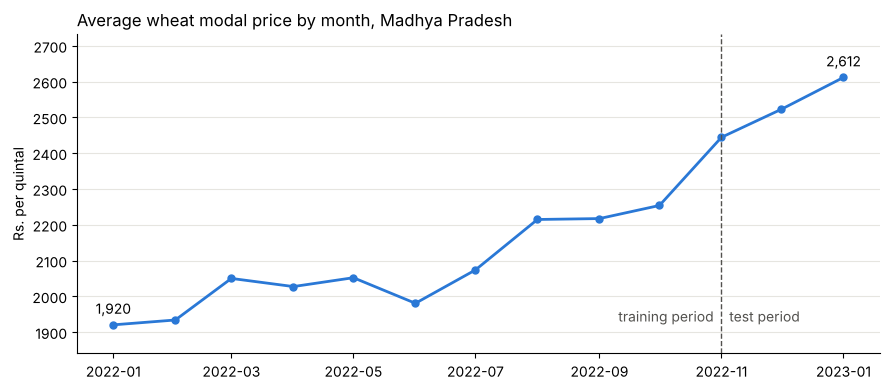

In [9]:
monthly = df.set_index("date")["modal_price"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values, color="#2a78d6", linewidth=2, marker="o", markersize=5)
split = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
ax.axvline(split, color="#52514e", linestyle="--", linewidth=1)
ax.text(split, monthly.min(), "  test period", color="#52514e", va="bottom")
ax.text(split, monthly.min(), "training period  ", color="#52514e", va="bottom", ha="right")
for when in (monthly.index[0], monthly.index[-1]):
    ax.annotate(f"{monthly[when]:,.0f}", (when, monthly[when]), textcoords="offset points",
                xytext=(0, 8), ha="center")
ax.set_title("Average wheat modal price by month, Madhya Pradesh", loc="left")
ax.set_ylabel("Rs. per quintal")
ax.set_ylim(monthly.min() - 80, monthly.max() + 120)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Models

Two feature sets are compared:

- **A.** weather + season + supply
- **B.** the same plus lagged prices

Train on dates up to `TRAIN_END`, test on later dates. Features are standardised; ridge and
lasso penalties are chosen with time-ordered cross-validation. Two naive baselines are included.

In [10]:
TARGET = "modal_price"
BASE_FEATURES = ["log_arrivals", "sharbati_share", "n_markets", "harvest_season",
                 "days_from_start", "rain_30d", "rain_90d", "tmax_30d", "tmax_90d",
                 "tmin_30d", "tmin_90d"]
LAG_FEATURES = ["price_lag1", "price_prev5_mean", "days_since_prev"]
ALPHAS = np.logspace(-3, 3, 40)


def score(name, feature_set, y_true, y_pred, alpha=np.nan):
    return {"feature_set": feature_set, "model": name,
            "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
            "mae": mean_absolute_error(y_true, y_pred),
            "r2": r2_score(y_true, y_pred), "alpha": alpha}


def evaluate(data, features, feature_set):
    data = data.dropna(subset=features + [TARGET]).sort_values("date")
    X = pd.get_dummies(data[features + ["district"]], columns=["district"],
                       drop_first=True, dtype=float)
    y = data[TARGET]
    is_train = data["date"] <= TRAIN_END
    X_train, X_test, y_train, y_test = X[is_train], X[~is_train], y[is_train], y[~is_train]

    cv = TimeSeriesSplit(n_splits=5)
    models = {"Linear": LinearRegression(),
              "Ridge": RidgeCV(alphas=ALPHAS, cv=cv),
              "Lasso": LassoCV(alphas=ALPHAS, cv=cv, max_iter=50_000)}

    scores, coefficients = [], {}
    for name, model in models.items():
        pipeline = make_pipeline(StandardScaler(), model).fit(X_train, y_train)
        scores.append(score(name, feature_set, y_test, pipeline.predict(X_test),
                            getattr(model, "alpha_", np.nan)))
        coefficients[name] = pd.Series(model.coef_, index=X.columns)

    scores.append(score("Baseline: training mean", feature_set, y_test,
                        np.full(len(y_test), y_train.mean())))
    if "price_lag1" in features:
        scores.append(score("Baseline: previous day's price", feature_set, y_test,
                            data.loc[~is_train, "price_lag1"]))

    coef_table = pd.DataFrame(coefficients)
    coef_table = coef_table[~coef_table.index.str.startswith("district_")]
    print(f"{feature_set}: {len(X_train):,} training rows, {len(X_test):,} test rows")
    return pd.DataFrame(scores), coef_table


results_a, coef_a = evaluate(df, BASE_FEATURES, "A. Weather + season + supply")
results_b, coef_b = evaluate(df, BASE_FEATURES + LAG_FEATURES, "B. Same + lagged prices")
results = pd.concat([results_a, results_b], ignore_index=True)
results.round(3)

A. Weather + season + supply: 13,171 training rows, 3,680 test rows


B. Same + lagged prices: 13,021 training rows, 3,680 test rows


,feature_set,model,rmse,mae,r2,alpha
0,A. Weather + season + supply,Linear,215.075,168.076,-0.151,NaN
1,A. Weather + season + supply,Ridge,306.722,264.527,-1.340,492.388
2,A. Weather + season + supply,Lasso,225.704,180.824,-0.267,0.412
3,A. Weather + season + supply,Baseline: training mean,497.349,458.000,-5.153,NaN
4,B. Same + lagged prices,Linear,152.324,88.594,0.423,NaN
5,B. Same + lagged prices,Ridge,185.730,139.586,0.142,701.704
6,B. Same + lagged prices,Lasso,169.956,120.013,0.281,4.924
7,B. Same + lagged prices,Baseline: training mean,495.430,455.992,-5.106,NaN
8,B. Same + lagged prices,Baseline: previous day's price,183.615,90.694,0.161,NaN


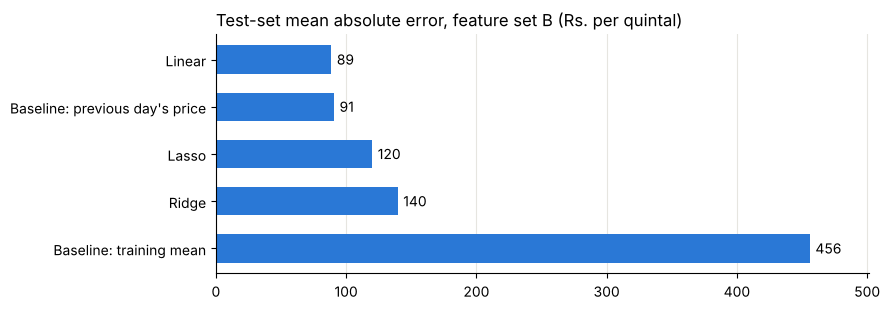

In [11]:
plot_data = results_b.sort_values("mae", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(plot_data["model"], plot_data["mae"], color="#2a78d6", height=0.6)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("Test-set mean absolute error, feature set B (Rs. per quintal)", loc="left")
ax.set_xlim(0, plot_data["mae"].max() * 1.1)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Coefficients

Standardised coefficients: the change in price (Rs./quintal) for a one-standard-deviation
change in the feature. District dummies are omitted.

In [12]:
coef_a.round(2)

,Linear,Ridge,Lasso
log_arrivals,25.09,22.70,25.56
sharbati_share,23.88,22.93,23.23
n_markets,3.98,4.99,2.89
harvest_season,58.55,42.48,51.51
days_from_start,131.65,91.73,128.71
rain_30d,5.49,9.15,6.81
rain_90d,0.71,16.93,0.00
tmax_30d,-60.21,-33.79,-59.96
tmax_90d,5.36,-19.61,0.00
tmin_30d,-17.59,-0.20,-0.00


In [13]:
coef_b.round(2)

,Linear,Ridge,Lasso
log_arrivals,23.22,19.67,13.17
sharbati_share,20.76,19.41,12.17
n_markets,4.49,4.99,0.00
harvest_season,29.55,17.59,0.00
days_from_start,69.52,40.95,12.36
rain_30d,3.36,4.73,0.00
rain_90d,0.42,7.89,9.37
tmax_30d,-25.21,-16.74,-0.70
tmax_90d,17.17,-7.03,-0.00
tmin_30d,-39.22,-4.37,-0.00


In [14]:
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
results.round(4).to_csv(RESULTS_DIR / "model_results_notebook.csv", index=False)

## Findings

- **Weather, season and supply alone do not predict the test months** (negative R²). Prices
  rose steadily, so the test period lies above anything in the training data.
- **With lagged prices, linear regression is the best model**, but only slightly better than
  using the previous day's price.
- **Ridge and lasso do not beat ordinary least squares here.** With about 13,000 training rows
  and about 60 features, overfitting is not the problem; the penalty shrinks the time-trend
  coefficient that the model needs to follow rising prices.
- **Lasso drops most weather features once recent prices are included**, because recent prices
  already carry that information.
- **One year of data is the main limitation**: seasonality cannot be separated from the
  2022 price rise.